# Module 03 — Sunday: Beginner-Friendly ML Workshop

**Platform:** Jupyter Notebook or Google Colab. **Method:** understand → run → inspect → practice.

The dataset is synthetic and only for training. The same notebook can run on either platform. Run the setup once, then execute cells from top to bottom.

## Libraries for preprocessing, model saving and a prediction app
Today we still use **scikit-learn** for ML. New tools include **joblib** (save/load Python model objects) and **Streamlit** (build a simple interactive web interface).

**Notebook setup (run only if missing):**
```python
%pip install scikit-learn joblib streamlit
```
**Terminal equivalent:** `python -m pip install -U scikit-learn joblib streamlit`.

Important scikit-learn modules:
- `sklearn.impute` → `SimpleImputer` fills missing inputs.
- `sklearn.preprocessing` → `StandardScaler` scales numbers and `OneHotEncoder` encodes text categories.
- `sklearn.compose` → `ColumnTransformer` prepares different columns differently.
- `sklearn.pipeline` → `Pipeline` links preparation and modeling so they can be saved together.
- `sklearn.cluster` → `KMeans`; `sklearn.model_selection` → `GridSearchCV`.

**Running the Streamlit app:** Create `app.py` and use `streamlit run app.py` in your **computer's terminal or Codespaces terminal** after installing Streamlit. This command is *not* a Python statement to paste into a normal notebook cell; Colab would need additional app-hosting/tunneling setup. Do not open unknown `.joblib` files.

In [ ]:
# Import scikit-learn so we can display the installed version used by the ML examples.
import sklearn
# Import joblib, which serializes trained pipelines to disk and restores them later.
import joblib
# SimpleImputer learns replacement values (such as a median) for missing feature entries.
from sklearn.impute import SimpleImputer
# Pipeline runs preprocessing and prediction steps in a fixed order.
from sklearn.pipeline import Pipeline
# KMeans assigns similar feature rows to clusters without using Pass/Fail labels.
from sklearn.cluster import KMeans
# importlib.util lets us check whether Streamlit is installed without launching an app.
import importlib.util
# Display the scikit-learn version so learners can troubleshoot differences in parameter names.
print("scikit-learn:", sklearn.__version__)
# Display the version of joblib used later to save and reload our fitted pipeline.
print("joblib:", joblib.__version__)
# find_spec returns None when Streamlit is not installed; 'is not None' converts that into True/False.
print("Streamlit installed:", importlib.util.find_spec("streamlit") is not None)
# If Streamlit is missing, install it in a notebook cell with: %pip install streamlit

**Line-by-line code walkthrough**

- `import sklearn  # The Machine Learning package.` — The Machine Learning package.
- `import joblib  # Save or load a trained Python model.` — Save or load a trained Python model.
- `from sklearn.impute import SimpleImputer  # Handle missing values.` — Handle missing values.
- `from sklearn.pipeline import Pipeline  # Connect several ML steps.` — Connect several ML steps.
- `from sklearn.cluster import KMeans  # A clustering algorithm.` — A clustering algorithm.
- `import importlib.util  # Check an optional package without importing it.` — Check an optional package without importing it.
- `print("scikit-learn:", sklearn.__version__)  # Package check.` — Package check.
- `print("joblib:", joblib.__version__)  # Saving tool check.` — Saving tool check.
- `print("Streamlit installed:", importlib.util.find_spec("streamlit") is not None)` — Display the computed value or model result.

**2-minute student check:** Which tool saves a fitted model? Which tool provides an app interface? Should `streamlit run app.py` be typed into a regular Python cell or a terminal?

**Instructor key:** joblib; Streamlit; a terminal. Inference should use the *saved preprocessing + model pipeline*, not a model with missing preprocessing.

## Setup — common imports and dataset

If `student_learning.csv` is in your working directory, use it. Otherwise, generate a small synthetic practice dataset so that **the notebook still runs** on both Jupyter and Colab.

In [ ]:
# Pandas reads the CSV into a labeled table, allowing selection by feature names.
import pandas as pd
# NumPy provides arrays and NaN values used in later preprocessing demonstrations.
import numpy as np
# Path constructs a filename that works across Windows, macOS, and Linux.
from pathlib import Path
# Handle a missing file gracefully so the notebook can tell learners what to upload.
try:
    # Point to the student dataset in the notebook's current working directory.
    path = Path("student_learning.csv")
    # Read each CSV row as a student record and each header as a DataFrame column.
    df = pd.read_csv(path)
    # shape returns (number_of_students, number_of_columns), not the data itself.
    print("Dataset shape:", df.shape)
    # head(3) previews the first three students to check column names and sample values.
    print(df.head(10))
# FileNotFoundError occurs when the CSV has not yet been uploaded to the notebook directory.
except FileNotFoundError:
    print("Student_learning file not found . please upload and try again")

**Line-by-line code walkthrough**

- `import pandas as pd  # Create and work with DataFrames.` — Create and work with DataFrames.
- `import numpy as np  # Work with numerical data.` — Work with numerical data.
- `from pathlib import Path  # Work with file paths on any OS.` — Work with file paths on any OS.
- `path = Path("student_learning.csv")` — Assign the resulting value to this variable for later use.
- `df = pd.read_csv(path)` — Read the CSV file into a Pandas DataFrame.
- `print("Dataset shape:", df.shape)` — Display the computed value or model result.
- `print(df.head(3))` — Display the computed value or model result.

## Our safe classification setup

We predict `passed` using information available before the final result. We **exclude** `final_score` because using the final outcome to predict passing would leak the answer.

In [ ]:
# train_test_split separates students used to learn patterns from students used to evaluate them.
from sklearn.model_selection import train_test_split
# These four continuous/count features can be used by algorithms that expect numerical inputs.
num = ["hours_studied", "attendance", "practice_tests", "sleep_hours"]
# Remove the Pass/Fail target and final exam score: final_score would leak the answer at prediction time.
X = df.drop(columns=["passed", "final_score"])
# Keep passed as the true class label: 0 for Fail, 1 for Pass.
y = df["passed"]
# Reserve 20% for testing; seed 42 repeats the split; stratify keeps Pass/Fail ratios similar.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y)
# Print row/column counts so we can verify that only the training portion will be fitted.
print("Training:", X_train.shape, "Testing:", X_test.shape)

**Line-by-line code walkthrough**

- `from sklearn.model_selection import train_test_split` — Import the functions or models needed for this step.
- `num = ["hours_studied", "attendance", "practice_tests", "sleep_hours"]` — Assign the resulting value to this variable for later use.
- `X = df.drop(columns=["passed", "final_score"])` — Create a new table without the specified columns or rows.
- `y = df["passed"]` — Assign the resulting value to this variable for later use.
- `X_train, X_test, y_train, y_test = train_test_split(` — Split features and labels into matching training and test groups.
- `X, y, test_size=0.20, random_state=42, stratify=y` — Assign the resulting value to this variable for later use.
- `print("Training:", X_train.shape, "Testing:", X_test.shape)` — Display the computed value or model result.

In [ ]:
# For an introductory example, use two numerical measurements instead of all five feature columns.
# Each row is a student; the columns are study hours and attendance percentage.
Xn = df[["hours_studied", "attendance"]]
# Reuse the Pass/Fail labels but retain 20% of students for checking predictions later.
# random_state=42 fixes the random split; stratify=y approximately preserves class balance.
Xt, Xv, yt, yv = train_test_split(
    Xn, y, test_size=.20, random_state=42, stratify=y
)
# Reuse this exact column list when fitting and predicting with tree-based models.
features = ["hours_studied", "attendance"]
# Confirm that the two-feature training and validation variables are available.
print("Ready for numerical demonstrations.")

**Line-by-line code walkthrough**

- `Xn = df[["hours_studied", "attendance"]]` — Assign the resulting value to this variable for later use.
- `Xt, Xv, yt, yv = train_test_split(` — Split features and labels into matching training and test groups.
- `Xn, y, test_size=.20, random_state=42, stratify=y` — Assign the resulting value to this variable for later use.
- `features = ["hours_studied", "attendance"]` — Assign the resulting value to this variable for later use.
- `print("Ready for numerical demonstrations.")` — Display the computed value or model result.

## Lesson 01 — Why Preprocessing Belongs in ML

**What it means:** Real datasets may have missing numeric values, inconsistent categories and features measured in different units. Preprocessing converts them into usable inputs.

**Why it is useful:** Training-only fitting matters: fill values, category mappings and scaling parameters must be learned on training rows, then reused on test and new rows.

**Real situation:** study_method contains text labels like group and video; hours_studied is numeric. Different types need different preprocessing.

**Important terms:** **Imputation:** Fill missing values using a learned rule; **Encoding:** Convert category labels into numbers; **Scaling:** Put numerical features on comparable scales

**Workflow:** Split the dataset → Choose each column type → Fit steps on train data → Apply to test and new rows

**Code example:** Read the comments, run the cell, then explain what changed. Predictions and evaluation scores are examples, not guarantees about real learners.

In [ ]:
# Pandas reads the CSV into a labeled table, allowing selection by feature names.
import pandas as pd
# NumPy provides arrays and NaN values used in later preprocessing demonstrations.
import numpy as np
# Path constructs a filename that works across Windows, macOS, and Linux.
from pathlib import Path
# Handle a missing file gracefully so the notebook can tell learners what to upload.
try:
    # Point to the student dataset in the notebook's current working directory.
    path = Path("student_learning_messy.csv")
    # Read each CSV row as a student record and each header as a DataFrame column.
    df2 = pd.read_csv(path)
    # shape returns (number_of_students, number_of_columns), not the data itself.
    print("Dataset shape:", df2.shape)
    # head(3) previews the first three students to check column names and sample values.
    print(df2.head(10))
# FileNotFoundError occurs when the CSV has not yet been uploaded to the notebook directory.
except FileNotFoundError:
    print("Student_learning file not found . please upload and try again")

In [ ]:
# isna() flags each missing entry; sum() counts missing values separately in each column.
print(df2.isna().sum())
# dtypes reveals whether fields are numeric, text/object, or another data type before preprocessing.
print(df2.dtypes)
# value_counts() counts students in each study_method category to inform encoding and imputation.
print(df2["study_method"].value_counts())
# Choose a filling or encoding strategy after inspecting actual missingness and column types.

**Line-by-line code walkthrough**

- `print(df.isna().sum())  # Missing counts` — Missing counts
- `print(df.dtypes)  # Data types` — Data types
- `print(df["study_method"].value_counts())` — Display the computed value or model result.

**How to interpret the result:** The dataset may have no missing cells. This check still belongs in every new project. The optional messy CSV lets students try real filling operations.

**Common mistake:** Never calculate missing-value replacements using the entire dataset before splitting; this can leak test information.

### Student practice

Why is filling missing values before splitting the data risky?

Write your answer in a new code cell. Explain the result in one sentence.

### Instructor solution and explanation

The replacement average or category may be influenced by held-out test records; fit the imputer on training rows.

**Teaching note:** Ask students to explain the reasoning, not only the final value.

## Lesson 02 — Missing Values with SimpleImputer

**What it means:** SimpleImputer fills missing values with a learned statistic such as the median for numbers or the most frequent value for categories.

**Why it is useful:** Median is often a helpful starting point when numeric values have unusual extremes. Missing values are not always random, so document the choice.

**Real situation:** If hours_studied is missing, the imputer can use the median value from the training set without inventing a new student record.

**Important terms:** **strategy="median":** Use training-set numeric median; **strategy="most_frequent":** Use most common training value; **fit_transform():** Learn filling rule and apply it

**Workflow:** Identify missing columns → Create imputer → Fit on train rows → Reuse on new/test data

**Code example:** Read the comments, run the cell, then explain what changed. Predictions and evaluation scores are examples, not guarantees about real learners.

In [ ]:
# NumPy makes a 2D array so SimpleImputer can analyze one feature column over several records.
import numpy as np
# SimpleImputer computes a replacement statistic during fit and fills missing cells during transform.
from sklearn.impute import SimpleImputer
# Three rows represent three students; the middle student has an unknown value (np.nan).
a = np.array([[2.], [np.nan], [9.],[12.],[np.nan]]) 
# Median uses the nonmissing values 2 and 9; their median is (2 + 9) / 2 = 5.5.
imp = SimpleImputer(strategy="median")
# Show (3, 1): three student records and one feature column.
print("before transformation\n",a)
# fit_transform learns median 5.5 and replaces nan, returning [[2.], [5.5], [9.]].
print("After Transformation\n",imp.fit_transform(a))

In [ ]:
# NumPy makes a 2D array so SimpleImputer can analyze one feature column over several records.
import numpy as np
# SimpleImputer computes a replacement statistic during fit and fills missing cells during transform.
from sklearn.impute import SimpleImputer
# Three rows represent three students; the middle student has an unknown value (np.nan).
a = df2[["hours_studied","attendance",]]
b=df2[["study_method"]]
# Median uses the nonmissing values 2 and 9; their median is (2 + 9) / 2 = 5.5.
imp = SimpleImputer(strategy="median")
imp2=SimpleImputer(strategy="most_frequent")
# Show (3, 1): three student records and one feature column.
print(b)
# fit_transform learns median 5.5 and replaces nan, returning [[2.], [5.5], [9.]].
a=imp2.fit_transform(b)
print(b)

**Line-by-line code walkthrough**

- `import numpy as np` — Import the Python package used in the example.
- `from sklearn.impute import SimpleImputer` — Import the functions or models needed for this step.
- `a = np.array([[2.], [np.nan], [8.]])` — Assign the resulting value to this variable for later use.
- `imp = SimpleImputer(strategy="median")` — Assign the resulting value to this variable for later use.
- `print(imp.fit_transform(a))` — Display the computed value or model result.

**How to interpret the result:** The missing second value becomes 5 because the observed values 2 and 8 have median 5.

**Common mistake:** Never assume that a missing cell means zero. Zero study hours and “unknown study hours” are different information.

### Student practice

Use strategy="mean" on [2, NaN, 10]. What fills the blank?

Write your answer in a new code cell. Explain the result in one sentence.

### Instructor solution and explanation

The mean of known values is (2 + 10)/2 = 6. The missing value becomes 6.

**Teaching note:** Ask students to explain the reasoning, not only the final value.

**Runnable practice solution:** Execute this code and explain the output. The previous section explains why the answer works.

In [ ]:
# Practice solution: replace the one missing entry with the mean of the observed values 2 and 10.
# NumPy provides np.nan, which represents the missing numerical value.
import numpy as np
# SimpleImputer can learn a column mean and insert it wherever values are missing.
from sklearn.impute import SimpleImputer
# Shape (3, 1): three observations of the SAME feature, not three separate feature columns.
x = np.array([[2.], [np.nan], [10.]])
# Mean imputation calculates (2 + 10) / 2 = 6; output becomes [[2.], [6.], [10.]].
print(SimpleImputer(strategy="mean").fit_transform(x))

**Line-by-line code walkthrough**

- `import numpy as np` — Import the Python package used in the example.
- `from sklearn.impute import SimpleImputer` — Import the functions or models needed for this step.
- `x = np.array([[2.], [np.nan], [10.]])` — Assign the resulting value to this variable for later use.
- `print(SimpleImputer(strategy="mean").fit_transform(x))` — Display the computed value or model result.

In [ ]:
# NumPy makes a 2D array so SimpleImputer can analyze one feature column over several records.
import numpy as np
# SimpleImputer computes a replacement string during fit and fills missing cells during transform.
from sklearn.impute import SimpleImputer
b=df2[["study_method"]]
print(df2["study_method"].value_counts())
imp2=SimpleImputer(strategy="most_frequent")
print(b)
b=imp2.fit_transform(b)
print(b)

## Lesson 03 — Category Encoding

**What it means:** One-hot encoding creates separate indicator columns for categorical values. With categories group, self and video, each category becomes a 0/1 column.

**Why it is useful:** Encoding must learn the training categories and handle new, previously unseen categories safely. This is better than assigning arbitrary category numbers.

**Real situation:** For study_method = video, the video indicator becomes 1 while other method indicators become 0.

**Important terms:** **OneHotEncoder:** Convert categories into indicator columns; **handle_unknown:** Choose behavior for unseen categories; **Sparse output:** Compact representation of mostly zeros

**Workflow:** Select text column → Fit encoder on train → Transform to 0/1 columns → Apply same mapping later

**Code example:** Read the comments, run the cell, then explain what changed. Predictions and evaluation scores are examples, not guarantees about real learners.

In [ ]:
# OneHotEncoder converts text categories into separate 0/1 feature columns.
from sklearn.preprocessing import OneHotEncoder
# Pandas provides the named 'method' column that the encoder will process.
import pandas as pd
# Four rows are four study-method observations; 'video' occurs twice.
d = pd.DataFrame({  "method":
    ["video", "group", "video", "self"]})
# sparse_output=False returns a normal dense array for easy printing in this tiny example.
# handle_unknown='ignore' prevents errors when a future row contains an unseen method.
enc = OneHotEncoder( categories=[['video','self','group']],
                    sparse_output=False,
                    handle_unknown="ignore")
# fit learns categories ('group', 'self', 'video'); transform returns one indicator per category.
result = enc.fit_transform(d)
print(result)
print(pd.DataFrame(result, columns=enc.get_feature_names_out()))

In [ ]:
# OneHotEncoder converts text categories into separate 0/1 feature columns.
from sklearn.preprocessing import OneHotEncoder
# Pandas provides the named 'method' column that the encoder will process.
import pandas as pd
# Four rows are four study-method observations; 'video' occurs twice.
d = df[["study_method"]]
# sparse_output=False returns a normal dense array for easy printing in this tiny example.
# handle_unknown='ignore' prevents errors when a future row contains an unseen method.
enc = OneHotEncoder(sparse_output=False,
                    handle_unknown="ignore")
# fit learns categories ('group', 'self', 'video'); transform returns one indicator per category.
result = enc.fit_transform(d)
print(result[:5])
print(pd.DataFrame(result, columns=enc.get_feature_names_out()))

**Line-by-line code walkthrough**

- `from sklearn.preprocessing import OneHotEncoder` — Import the functions or models needed for this step.
- `import pandas as pd` — Import the Python package used in the example.
- `d = pd.DataFrame({"method":` — Assign the resulting value to this variable for later use.
- `enc = OneHotEncoder(sparse_output=False,` — Assign the resulting value to this variable for later use.
- `handle_unknown="ignore")` — Assign the resulting value to this variable for later use.
- `print(enc.fit_transform(d))` — Display the computed value or model result.

**How to interpret the result:** The output is a numeric matrix with a column for each observed method. Each row has a 1 for its category.

**Common mistake:** Do not code group=1, self=2, video=3 unless those numbers have real ordered meaning.

### Student practice

What happens when handle_unknown="ignore" sees a method not present during training?

Write your answer in a new code cell. Explain the result in one sentence.

### Instructor solution and explanation

For that feature it returns zeros for the unknown category instead of raising an error.

**Teaching note:** Ask students to explain the reasoning, not only the final value.

## Lesson 04 — Feature Scaling

**What it means:** StandardScaler shifts each numeric feature around mean zero and scales it using standard deviation. It is helpful for models sensitive to feature magnitude.

**Why it is useful:** Study hours may range 0–10, while attendance ranges 40–100. Scaling makes these comparable in algorithms such as logistic regression and K-means.

**Real situation:** A student with attendance 80 and 5 study hours is represented in standardized units after fitting the scaler on training data.

**Important terms:** **Mean:** Average of training feature values; **Std. deviation:** Spread used to divide centered values; **transform():** Apply learned train-set scaling

**Workflow:** Fit scaler on training → Save mean and spread → Transform train values → Transform test with same scaler

**Code example:** Read the comments, run the cell, then explain what changed. Predictions and evaluation scores are examples, not guarantees about real learners.

In [ ]:
# StandardScaler places numerical features on a comparable scale using training statistics.
from sklearn.preprocessing import StandardScaler
# Three rows, one feature: values 1, 2, and 3 will determine mean=2 and std≈0.816.
a = [[1.], [2.], [3.]]
# Create the scaler; it has not learned a mean or standard deviation until fit is called.
scaler = StandardScaler()
# Fit using [1,2,3], subtract mean 2 and divide by population std; round for readability.
print(scaler.fit_transform(a).round(2))
# Transform 4 with the SAME learned mean/std (about 2.45); do not fit again on the new value.
print(scaler.transform([[4.]]).round(2))

**Line-by-line code walkthrough**

- `from sklearn.preprocessing import StandardScaler` — Import the functions or models needed for this step.
- `a = [[1.], [2.], [3.]]` — Assign the resulting value to this variable for later use.
- `scaler = StandardScaler()` — Assign the resulting value to this variable for later use.
- `print(scaler.fit_transform(a).round(2))` — Display the computed value or model result.
- `print(scaler.transform([[2.]]).round(2))` — Display the computed value or model result.

**How to interpret the result:** The middle value becomes approximately 0 after standardization because it equals the mean. New records use the same learned mean and spread.

**Common mistake:** Do not fit StandardScaler separately on the test data: this would make train and test use different transformations.

### Student practice

Do decision trees usually require StandardScaler? Why or why not?

Write your answer in a new code cell. Explain the result in one sentence.

### Instructor solution and explanation

Usually no. Trees split by value thresholds and are not sensitive to numerical scales in the same way as distance-based models.

**Teaching note:** Ask students to explain the reasoning, not only the final value.

## Lesson 05 — ColumnTransformer

**What it means:** ColumnTransformer applies separate preprocessing steps to selected column groups, then joins the results into one numeric feature matrix.

**Why it is useful:** This connects Pandas columns to a model safely. Numeric columns can receive imputation and scaling; text categories receive imputation and encoding.

**Real situation:** hours_studied and attendance go through numeric processing. study_method goes through OneHotEncoder in the same fitted transformer.

**Important terms:** **Numeric columns:** Features needing imputation and scaling; **Category columns:** Features needing categorical encoding; **ColumnTransformer:** Combine transformers by named column lists

**Workflow:** Declare numeric columns → Declare category columns → Build each transformer → Combine transformations

**Code example:** Read the comments, run the cell, then explain what changed. Predictions and evaluation scores are examples, not guarantees about real learners.

In [ ]:
# Pandas lets us compare the unprocessed student example and its encoded/scaled features.
import pandas as pd
# ColumnTransformer joins the output of numeric and categorical transformations.
from sklearn.compose import ColumnTransformer
# StandardScaler scales study hours; OneHotEncoder turns study_method into category indicators.
from sklearn.preprocessing import StandardScaler, OneHotEncoder
# Create a small five-student demonstration table; this temporarily replaces the variable df.
# Later lesson cells reload student_learning.csv before using the full dataset again.
df = pd.DataFrame({
    "hours_studied": [2, 4, 6, 8, 10],
    "study_method": ["Book", "Video", "Book", "Online", "Video"]
})
# Print the original two columns so students can compare before and after transformations.
print("BEFORE TRANSFORMATION:")
print(df)
# Apply StandardScaler only to hours_studied and OneHotEncoder only to study_method.
# This demo replaces the variable prep; the later classification pipeline uses this new prep.
prep = ColumnTransformer([
    # Standardize each hour value relative to the five-hour observations' mean and spread.
    ("num", StandardScaler(), ["hours_studied"]),
    # Create separate indicator columns for Book, Online and Video; unknown categories are ignored.
    ("cat", OneHotEncoder(handle_unknown="ignore"), ["study_method"])
])
# Learn scaling/category parameters from this example and transform its five rows.
transformed_data = prep.fit_transform(df)
# Retrieve readable headers, including the one-hot study_method category names.
columns = prep.get_feature_names_out()
# Attach those headers to the transformed numeric matrix for easier inspection.
transformed_df = pd.DataFrame(transformed_data,columns=columns)
# Print the processed table with values rounded to two decimals (without changing the data).
print("\nAFTER TRANSFORMATION:")
print(transformed_df.round(2))

In [ ]:
# ColumnTransformer sends different feature subsets to different preprocessing methods.
from sklearn.compose import ColumnTransformer
# StandardScaler standardizes hours_studied based on the mean and std of the fit data.
from sklearn.preprocessing import StandardScaler
# OneHotEncoder converts each study-method category into its own binary indicator column.
from sklearn.preprocessing import OneHotEncoder
# Rebuild the same two-branch preprocessing definition for the full training table used next.
prep = ColumnTransformer([
 # 'num': center and scale hours_studied, using fitted training statistics.
 ("num", StandardScaler(), ["hours_studied"]),
 # 'cat': one-hot encode study_method and ignore unfamiliar values during future predictions.
 ("cat", OneHotEncoder(handle_unknown="ignore"),
  ["study_method"])])

**Line-by-line code walkthrough**

- `from sklearn.compose import ColumnTransformer` — Import the functions or models needed for this step.
- `from sklearn.preprocessing import StandardScaler` — Import the functions or models needed for this step.
- `from sklearn.preprocessing import OneHotEncoder` — Import the functions or models needed for this step.
- `prep = ColumnTransformer([` — Apply separate steps to selected column groups.
- `("cat", OneHotEncoder(handle_unknown="ignore"),` — Assign the resulting value to this variable for later use.

**How to interpret the result:** One transformer prepares both numeric and text features consistently. In a full pipeline, we will add imputation and the estimator.

**Common mistake:** Do not manually encode the test data using a different set of categories or a different column order.

### Student practice

Which preprocessor would you choose for attendance, and which for study_method?

Write your answer in a new code cell. Explain the result in one sentence.

### Instructor solution and explanation

Attendance is numerical (optional imputation/scaling). study_method is categorical (imputation/OneHotEncoder).

**Teaching note:** Ask students to explain the reasoning, not only the final value.

## Lesson 06 — Pipeline — Link Preparation and Model

**What it means:** A Pipeline chains preprocessing and a model. Calling fit() learns each training transformation and fits the estimator without using held-out test rows.

**Why it is useful:** The same object handles predictions on new records, which reduces the risk of missing an encoding step when deploying the model.

**Real situation:** A complete pipeline reads raw student features, prepares text/numeric columns, then predicts whether the student passes.

**Important terms:** **Pipeline steps:** A named sequence ending with an estimator; **fit():** Fit all transformers and final model; **predict():** Transform new input and predict with same rules

**Workflow:** Build preprocessing → Add estimator → Fit on training only → Predict on untouched test

**Code example:** Read the comments, run the cell, then explain what changed. Predictions and evaluation scores are examples, not guarantees about real learners.

In [ ]:
# Pipeline chains preprocessing and classifier training so their fitted settings stay together.
from sklearn.pipeline import Pipeline
# LogisticRegression models the probability of the Pass class from processed student features.
from sklearn.linear_model import LogisticRegression
# First run the previously defined ColumnTransformer; then fit the classifier to its output.
prep = ColumnTransformer([
 # 'num': center and scale hours_studied, using fitted training statistics.
 ("num", StandardScaler(), ["hours_studied"]),
 # 'cat': one-hot encode study_method and ignore unfamiliar values during future predictions.
 ("cat", OneHotEncoder(handle_unknown="ignore"),
  ["study_method"])])
pipe = Pipeline([
    ("preprocess", prep),
    # max_iter=1000 permits up to 1000 solver steps if the logistic-regression fit needs them.
    ("model", LogisticRegression(max_iter=1000))
])
# Learn the scaler, encoder categories, and logistic-regression coefficients from training records.
pipe.fit(X_train, y_train)
# print(pipe.predict(X_test))         # Predicted classes
# print(pipe.score(X_test, y_test))   # Accuracy
# print(pipe.named_steps["model"].n_iter_)  # Iterations used

**Line-by-line code walkthrough**

- `from sklearn.pipeline import Pipeline` — Import the functions or models needed for this step.
- `from sklearn.linear_model import LogisticRegression` — Import the functions or models needed for this step.
- `pipe = Pipeline([` — Combine preprocessing and prediction in one workflow.
- `("model", LogisticRegression(max_iter=1000))` — Assign the resulting value to this variable for later use.
- `pipe.fit(X_train, y_train)` — Fit the estimator using the provided training examples.

**How to interpret the result:** pipe.predict(X_test) automatically applies the learned ColumnTransformer before using LogisticRegression. It expects the same raw input column names.

**Common mistake:** The pipeline above requires prep and the train/test split from earlier. The full instructor notebook supplies and executes setup in order.

### Student practice

What advantage does Pipeline have over manually calling scaler.transform() and model.predict()?

Write your answer in a new code cell. Explain the result in one sentence.

### Instructor solution and explanation

It applies the same fitted transformations in the right order every time, reducing mistakes and leakage.

**Teaching note:** Ask students to explain the reasoning, not only the final value.

## Lesson 07 — Feature Engineering

**What it means:** Feature engineering creates new variables that express meaningful information. A well-designed feature may make a simple model more effective.

**Why it is useful:** Create features only from information available at prediction time. New features should be tested on held-out data, not assumed better.

**Real situation:** weekly_study_minutes = hours_studied × 60. A ratio or change feature might add information if it has a meaningful interpretation.

**Important terms:** **Derived feature:** A new column computed from existing inputs; **Domain knowledge:** Understanding how a feature relates to task; **Ablation:** Compare model with and without new feature

**Workflow:** Propose a sensible feature → Calculate without future data → Train comparable models → Keep it only if it helps

**Code example:** Read the comments, run the cell, then explain what changed. Predictions and evaluation scores are examples, not guarantees about real learners.

In [ ]:
# Reload the COMPLETE student dataset, replacing the five-row example made earlier.
df = pd.read_csv("student_learning.csv")
# Convert each student's study hours to minutes by multiplying the hours column by 60.
df["study_minutes"] = (df["hours_studied"] * 60)
# Compare the original hours with the engineered minutes for the first three students.
print(df[["hours_studied","study_minutes"]].head(3))
print(df.isna().sum())

**Line-by-line code walkthrough**

- `df = pd.read_csv("student_learning.csv")` — Read the CSV file into a Pandas DataFrame.
- `df["study_minutes"] = (` — Assign the resulting value to this variable for later use.
- `print(df[["hours_studied",` — Display the computed value or model result.

**How to interpret the result:** The new column converts hours to minutes. It is useful for demonstration but largely repeats the same information, so it may not improve a model.

**Common mistake:** Creating the target from known final scores and using that computed feature to predict itself is leakage.

### Student practice

Suggest one new feature using attendance and practice_tests. Explain whether it provides new information.

Write your answer in a new code cell. Explain the result in one sentence.

### Instructor solution and explanation

Example: practice_per_attendance = practice_tests / attendance (when attendance > 0). Test it rather than assuming it is better.

**Teaching note:** Ask students to explain the reasoning, not only the final value.

**Runnable practice solution:** Execute this code and explain the output. The previous section explains why the answer works.

In [ ]:
# Build a derived ratio from information available before a student's final result.
# copy() leaves the original df unchanged while we experiment with an extra feature.
copy_df = df.copy()
# Divide the number of practice tests by attendance; clip(lower=1) avoids dividing by zero.
# This is an instructional ratio, not a validated measure of a student's ability.
copy_df["tests_per_attendance"] = (
    copy_df["practice_tests"] / copy_df["attendance"].clip(lower=1)
)
# Show five students' source columns and the new ratio to verify the calculation.
print(copy_df[["attendance","practice_tests","tests_per_attendance"]].head())

**Line-by-line code walkthrough**

- `copy_df = df.copy()` — Assign the resulting value to this variable for later use.
- `copy_df["tests_per_attendance"] = (` — Assign the resulting value to this variable for later use.
- `copy_df["practice_tests"] / copy_df["attendance"].clip(lower=1)` — Assign the resulting value to this variable for later use.
- `print(copy_df[["attendance","practice_tests","tests_per_attendance"]].head())` — Display the computed value or model result.

## Lesson 08 — K-means Clustering

**What it means:** K-means is unsupervised learning. It separates numeric records into k groups by repeatedly assigning each record to its nearest cluster center.

**Why it is useful:** Clusters can help explore common patterns, but a cluster number is not a real-world diagnosis or a true label. Scaling matters because distance matters.

**Real situation:** Group students by hours_studied and attendance without using passed. Later inspect if groups differ in their habits.

**Important terms:** **k:** Number of groups chosen before fitting; **Centroid:** Average location of a cluster; **Label:** Assigned cluster number, not ground truth

**Workflow:** Choose numeric features → Scale values → Run K-means → Interpret clusters carefully

**Code example:** Read the comments, run the cell, then explain what changed. Predictions and evaluation scores are examples, not guarantees about real learners.

In [ ]:
# KMeans discovers groups of students with similar numeric feature values, without labels.
from sklearn.cluster import K Means
# StandardScaler keeps attendance percentages from dominating study-hour distances.
from sklearn.preprocessing import StandardScaler
# Use study hours and attendance as the two coordinates for each student's clustering input.
a = df[["hours_studied", "attendance"]]
# Fit scaling statistics on these features and return standardized coordinates for KMeans.
z = StandardScaler().fit_transform(a)
# Find three clusters; use 10 initial centroid choices and seed 42 for repeatability.
km = KMeans(n_clusters=10, random_state=42,
            n_init=10)
# Fit KMeans on scaled features and attach each student's cluster index (0, 1, or 2).
df["cluster"] = km.fit_predict(z)
print(df.head(20))


In [ ]:
#to see how clusters are being made
print( df.groupby("cluster")[["hours_studied", "attendance"]].mean())
#check size of each cluster
print(df.groupby("cluster").size()) 

In [ ]:
# Count how many students belong to each cluster.
# sort_index() displays cluster labels in numerical order: 0, 1, 2, 3, 4.
print(df["cluster"].value_counts().sort_index())

In [ ]:
# Find the lowest and highest study hours and attendance in each cluster.
# These values show the range of student observations within each group.
print(
    df.groupby("cluster")[["hours_studied", "attendance"]]
      .agg(["min", "max"])
)

In [ ]:
# Show count, mean, standard deviation, minimum, maximum, and percentiles.
# The 50% percentile is the median: the middle value when values are sorted.
print(
    df.groupby("cluster")[["hours_studied", "attendance"]].describe()
)

In [ ]:
# Display all students assigned to cluster 0.
# Change 0 to another cluster label to inspect that group.
print(df[df["cluster"] == 6])

In [ ]:
# Create one summary row for each cluster.
# size counts student rows; mean calculates the average of each selected feature.
summary = df.groupby("cluster").agg(
    students=("hours_studied", "size"),
    avg_hours=("hours_studied", "mean"),
    avg_attendance=("attendance", "mean")
)

# Round the displayed averages to two decimal places for easier reading.
print(summary.round(2))

**Line-by-line code walkthrough**

- `from sklearn.compose import ColumnTransformer` — to apply different preprocessing techniques to different columns.
- `from sklearn.pipeline import Pipeline` — Import the functions or models needed for this step.
- `from sklearn.impute import SimpleImputer` — Import the functions or models needed for this step.
- `from sklearn.preprocessing import OneHotEncoder, StandardScaler` — Import the functions or models needed for this step.
- `from sklearn.linear_model import LogisticRegression` — Import the functions or models needed for this step.
- `num_cols = ["hours_studied", "attendance", "practice_tests", "sleep_hours"]` — Assign the resulting value to this variable for later use.
- `cat_cols = ["study_method"]` — Assign the resulting value to this variable for later use.
- `prep = ColumnTransformer([` — Apply separate steps to selected column groups.
- `("num", Pipeline([("fill", SimpleImputer(strategy="median")),` — Combine preprocessing and prediction in one workflow.
- `("cat", Pipeline([("fill", SimpleImputer(strategy="most_frequent")),` — Combine preprocessing and prediction in one workflow.
- `("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat_cols)` — Assign the resulting value to this variable for later use.
- `pipe = Pipeline([("preprocess",prep),` — Combine preprocessing and prediction in one workflow.
- `("model",LogisticRegression(max_iter=1000))])` — Assign the resulting value to this variable for later use.
- `pipe.fit(X_train,y_train)` — Fit the estimator using the provided training examples.
- `print("Starting fitted pipeline ready.")` — Display the computed value or model result.

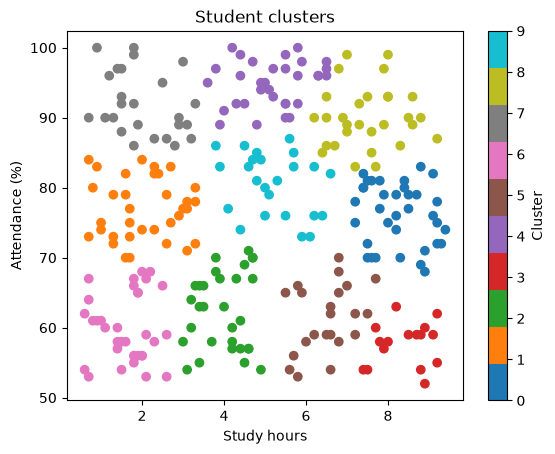

In [ ]:
import matplotlib.pyplot as plt

plt.scatter( df["hours_studied"], df["attendance"], c=df["cluster"],
    cmap="tab10" )
plt.xlabel("Study hours")
plt.ylabel("Attendance (%)")
plt.title("Student clusters")
plt.colorbar(label="Cluster")
plt.show()

**Line-by-line code walkthrough**

- `from sklearn.cluster import KMeans` — Import the functions or models needed for this step.
- `from sklearn.preprocessing import StandardScaler` — Import the functions or models needed for this step.
- `a = df[["hours_studied", "attendance"]]` — Assign the resulting value to this variable for later use.
- `z = StandardScaler().fit_transform(a)` — Learn a transformation and apply it to these inputs.
- `km = KMeans(n_clusters=3, random_state=42,` — Create a clustering model with the requested group count.
- `n_init=10)` — Assign the resulting value to this variable for later use.
- `df["cluster"] = km.fit_predict(z)` — Assign the resulting value to this variable for later use.

**How to interpret the result:** df.cluster now contains labels such as 0, 1 and 2. Those numbers are arbitrary; compare means of hours and attendance to describe each group.

**Common mistake:** Clusters do not mean students belong to fixed personality types. K-means will assign groups even when the data lacks clear natural clusters.

### Student practice

Why do we scale study hours and attendance before K-means?

Write your answer in a new code cell. Explain the result in one sentence.

### Instructor solution and explanation

K-means uses distances; the larger numerical range of attendance could otherwise dominate the smaller study-hour range.

**Teaching note:** Ask students to explain the reasoning, not only the final value.

## Lesson 09 — Choosing k and Understanding Clusters

**What it means:** The elbow method compares within-cluster inertia for several k values. Inertia usually decreases as k increases, so it is not itself proof of the best k.

**Why it is useful:** Compare cluster centers and sizes, check whether the groups are meaningful, and avoid over-interpreting noisy results.

**Real situation:** For student data, inspect average study hours and attendance for each cluster to describe what it represents.

**Important terms:** **Inertia:** Sum of squared distances to assigned centers; **Elbow:** A point of diminishing improvement; **Cluster profile:** Typical feature values of a group

**Workflow:** Try small k values → Record inertia → Compare size and profile → Describe limits honestly

**Code example:** Read the comments, run the cell, then explain what changed. Predictions and evaluation scores are examples, not guarantees about real learners.

In [63]:
# KMeans is used here to compare candidate numbers of clusters using inertia.
from sklearn.cluster import KMeans
# Repeat clustering with 2, 3, and 4 clusters to inspect how within-cluster distance changes.
for k in [2, 3, 10,20,21,25,30,31]:
    # Run 10 centroid initializations per k; seed the random choices for reproducible results.
    m = KMeans(n_clusters=k,
               n_init=10, random_state=42)
    # Fit cluster centers to z (the standardized study-hours and attendance matrix).
    # Use study hours and attendance as the two coordinates for each student's clustering input.
    a = df[["hours_studied", "attendance"]]
# Fit scaling statistics on these features and return standardized coordinates for KMeans.
    f = StandardScaler().fit_transform(a)
    m.fit(f)
    # inertia_ sums squared distances to assigned centroids; lower values favor tighter clusters.
    print(k, round(m.inertia_, 1))

2 336.8
3 197.9
10 49.4
20 23.3
21 21.4
25 17.8
30 13.8
31 13.4


**Line-by-line code walkthrough**

- `from sklearn.cluster import KMeans` — Import the functions or models needed for this step.
- `for k in [2, 3, 4]:` — Repeat the following indented statements for each value.
- `m = KMeans(n_clusters=k,` — Create a clustering model with the requested group count.
- `n_init=10, random_state=42)` — Assign the resulting value to this variable for later use.
- `m.fit(z)  # z is scaled numeric data` — z is scaled numeric data
- `print(k, round(m.inertia_, 1))` — Display the computed value or model result.

**How to interpret the result:** Inertia falls as k increases. Choose k using both the curve and whether groups are useful and understandable.

**Common mistake:** Do not claim a cluster represents successful students without comparing it against relevant outcomes and checking uncertainty.

### Student practice

If inertia always decreases with k, can we simply choose k=50?

Write your answer in a new code cell. Explain the result in one sentence.

### Instructor solution and explanation

No. Too many clusters can fragment the data; choose a practical number with meaningful cluster profiles.

**Teaching note:** Ask students to explain the reasoning, not only the final value.

## Lesson 10 — Hyperparameter Tuning

**What it means:** A hyperparameter is a setting chosen before training, such as tree depth. GridSearchCV tests a small list of settings using cross-validation.

**Why it is useful:** Tuning should be performed inside the training portion only. Afterwards, the selected model is evaluated once on the reserved test set.

**Real situation:** Try tree depth 2, 4 and 6. Compare validation scores, not only training scores, to choose a sensible level of complexity.

**Important terms:** **Parameter:** Value learned by fit, such as a coefficient; **Hyperparameter:** Choice made before fit, such as max_depth; **GridSearchCV:** Cross-validates candidate settings

**Workflow:** Define candidate settings → Run CV on training → Pick best validation score → Check reserved test once

**Code example:** Read the comments, run the cell, then explain what changed. Predictions and evaluation scores are examples, not guarantees about real learners.

In [ ]:
# GridSearchCV compares hyperparameter settings using repeated training/validation folds.
from sklearn.model_selection import GridSearchCV
# DecisionTreeClassifier predicts Pass/Fail by splitting features at learned thresholds.
from sklearn.tree import DecisionTreeClassifier
# Try tree depths 2, 4 and 6; cv=3 measures each candidate over three folds.
# The tree's random_state controls any randomness in fitting; this is not the data-split seed.
search = GridSearchCV(
 {"max_depth": [2, 3, 6]}, cv=5)
# Perform the depth search on NUMERIC TRAINING columns only; the held-out test set is untouched.
search.fit(X_train[num], y_train)
# Report the depth setting with the best average cross-validation score.
print(search.best_params_)

{'max_depth': 2}


**Line-by-line code walkthrough**

- `from sklearn.model_selection import GridSearchCV` — Import the functions or models needed for this step.
- `from sklearn.tree import DecisionTreeClassifier` — Import the functions or models needed for this step.
- `search = GridSearchCV(` — Test model settings by cross-validation.
- `DecisionTreeClassifier(random_state=42),` — Assign the resulting value to this variable for later use.
- `{"max_depth": [2, 4, 6]}, cv=3)` — Assign the resulting value to this variable for later use.
- `search.fit(X_train[num], y_train)` — Fit the estimator using the provided training examples.
- `print(search.best_params_)` — Display the computed value or model result.

**How to interpret the result:** best_params_ reports the cross-validated depth choice. It can differ across datasets; do not hardcode the “winning” depth in teaching materials.

**Common mistake:** Avoid tuning on X_test or repeatedly inspecting test performance after every grid. That quietly weakens the final evaluation.

### Student practice

What does cv=3 mean in GridSearchCV?

Write your answer in a new code cell. Explain the result in one sentence.

### Instructor solution and explanation

Each setting is evaluated across three training/validation folds within the supplied training set.

**Teaching note:** Ask students to explain the reasoning, not only the final value.

**Runnable practice solution:** Execute this code and explain the output. The previous section explains why the answer works.

In [ ]:
# Practice: select a Decision Tree depth using cross-validation, not test-set peeking.
# GridSearchCV evaluates each specified depth across three validation folds.
from sklearn.model_selection import GridSearchCV
# The base estimator is a DecisionTreeClassifier for predicting Pass/Fail labels.
from sklearn.tree import DecisionTreeClassifier
# Check depths 2, 4 and 6; cv=3 refits the model across three train/validation splits.
tuner = GridSearchCV(DecisionTreeClassifier(random_state=42),
                     {"max_depth": [2,4,6]}, cv=3)
# Search only the original training rows and their actual Pass/Fail outcomes.
tuner.fit(X_train[num], y_train)
# Display the winning hyperparameter setting chosen by average validation performance.
print("Best setting:", tuner.best_params_)

In [ ]:
# Average cross-validation accuracy of the winning depth.
print("Best CV accuracy:", tuner.best_score_)

# Test accuracy of the winning model, refitted on all training rows.
print("Test accuracy:", tuner.score(X_test[num], y_test))

**Line-by-line code walkthrough**

- `from sklearn.model_selection import GridSearchCV` — Import the functions or models needed for this step.
- `from sklearn.tree import DecisionTreeClassifier` — Import the functions or models needed for this step.
- `tuner = GridSearchCV(DecisionTreeClassifier(random_state=42),` — Test model settings by cross-validation.
- `{"max_depth": [2,4,6]}, cv=3)` — Assign the resulting value to this variable for later use.
- `tuner.fit(X_train[num], y_train)` — Fit the estimator using the provided training examples.
- `print("Best setting:", tuner.best_params_)` — Display the computed value or model result.

## Lesson 11 — Save, Load and Run New Predictions

**What it means:** joblib saves fitted Python/scikit-learn objects to disk. Saving the entire Pipeline keeps the encoding/scaling and model together.

**Why it is useful:** After loading, the model can run on new records without fitting again. New input must follow the original schema and feature meaning.

**Real situation:** Save a fitted pipeline to student_pass_pipeline.joblib; later load it in another session and predict incoming student records.

**Important terms:** **Artifact:** The saved fitted pipeline file; **joblib.dump():** Write a fitted Python object to disk; **joblib.load():** Read a trusted object back from disk

**Workflow:** Fit the pipeline → Save whole fitted object → Load from trusted file → Predict new rows

**Code example:** Read the comments, run the cell, then explain what changed. Predictions and evaluation scores are examples, not guarantees about real learners.

In [69]:
# joblib saves and reloads Python objects that include fitted scikit-learn parameters.
import joblib
# Write the ENTIRE fitted pipeline (preprocessing + classifier) to a file for later inference.
joblib.dump(pipe, "student_model.joblib")
# Restore the saved pipeline; load files only from trusted sources because joblib uses pickle.
loaded = joblib.load("student_model.joblib")
# Take two held-out examples with the same input columns, leaving the original test set unchanged.
#new = X_test.head(2).copy()
new = pd.DataFrame({
    "hours_studied": [7.6],
    "attendance": [90,],
    "practice_tests": [7,],
    "sleep_hours": [7,],
    "study_method": ["video"]
})
# Run preprocessing and Pass/Fail prediction through the restored pipeline without retraining.
print(loaded.predict(new))
new["predicted_pass"] = loaded.predict(new)
print(new)

[1]
   hours_studied  attendance  practice_tests  sleep_hours study_method  \
0            7.6          90               7            7        video   

   predicted_pass  
0               1  


In [70]:
# Values at the same position belong to the same student.
new_students = pd.DataFrame({
    "hours_studied": [6, 2, 8],
    "study_method": ["video", "self", "group"]
})

# Predict one result for each student.
predictions = loaded.predict(new_students)

# Display each student's inputs alongside the predicted class.
new_students["predicted"] = predictions
print(new_students)

ValueError: columns are missing: {'practice_tests', 'sleep_hours', 'attendance'}

**Line-by-line code walkthrough**

- `import joblib` — Import the Python package used in the example.
- `joblib.dump(pipe, "student_model.joblib")` — Save the fitted model or pipeline to a file.
- `loaded = joblib.load("student_model.joblib")` — Load a trusted fitted object from a file.
- `new = X_test.head(2).copy()` — Assign the resulting value to this variable for later use.
- `print(loaded.predict(new))` — Display the computed value or model result.

**How to interpret the result:** The loaded pipeline produces class labels for unseen test rows using the same preprocessing learned earlier.

**Common mistake:** Only load joblib files from trusted sources; serialized Python objects can execute code. Keep library versions compatible.

### Student practice

What happens if a new dataset is missing study_method?

Write your answer in a new code cell. Explain the result in one sentence.

### Instructor solution and explanation

The pipeline expects that required input column and will fail. Validate the input schema before prediction.

**Teaching note:** Ask students to explain the reasoning, not only the final value.

**Runnable practice solution:** Execute this code and explain the output. The previous section explains why the answer works.

In [ ]:
# Detect missing features before submitting records to the saved prediction pipeline.
# The training DataFrame's column names define the expected input schema.
required = list(X_train.columns)
# Simulate a malformed request by removing study_method from two held-out records.
new = X_test.head(2).drop(columns=["study_method"])
# Collect every required training column absent from the new input DataFrame.
missing = [col for col in required if col not in new.columns]
# The output should include study_method, warning that prediction inputs are incomplete.
print("Missing input columns:", missing)

**Line-by-line code walkthrough**

- `required = list(X_train.columns)` — Assign the resulting value to this variable for later use.
- `new = X_test.head(2).drop(columns=["study_method"])` — Create a new table without the specified columns or rows.
- `missing = [col for col in required if col not in new.columns]` — Assign the resulting value to this variable for later use.
- `print("Missing input columns:", missing)` — Display the computed value or model result.

## Lesson 12 — Responsible ML and Model Cards

**What it means:** Responsible use asks who the model affects, what data was used, whether results may be unfair, and which limitations are important to explain.

**Why it is useful:** A model card records the model purpose, input columns, dataset, evaluation method, performance, limitations and conditions where it should not be used.

**Real situation:** A student-support classifier should offer guidance, not automatically punish learners. Historical performance could reflect unequal access to resources.

**Important terms:** **Fairness:** Check errors and impacts across groups; **Privacy:** Avoid unnecessary sensitive information; **Model card:** A short, reproducible model description

**Workflow:** Explain intended use → Report held-out metrics → Describe limitations → Human review before action

**Code example:** Read the comments, run the cell, then explain what changed. Predictions and evaluation scores are examples, not guarantees about real learners.

In [71]:
# A model card records what a model predicts, the inputs it expects, and how it should be used.
model_card = {
  "task": "Teaching demo: pass prediction",  # This classroom classifier estimates Pass (1) vs Fail (0).
  "inputs": ["hours_studied", "attendance"],  # Example features provided to a student-risk model.
  "metric": "Test F1 and confusion matrix",  # Evaluate mistakes as well as overall accuracy.
  "limit": "Synthetic data; no real decisions"  # Do not make real student judgments from synthetic data.
}
# Read the limit field to emphasize that these examples are educational, not decision policies.
print(pd.Series(model_card))

task         Teaching demo: pass prediction
inputs          [hours_studied, attendance]
metric         Test F1 and confusion matrix
limit     Synthetic data; no real decisions
dtype: object


**Line-by-line code walkthrough**

- `model_card = {` — Assign the resulting value to this variable for later use.
- `print(model_card["limit"])` — Display the computed value or model result.

**How to interpret the result:** The printed limitation reminds users that this exercise uses synthetic data and should not be treated as a reliable real-world student assessment tool.

**Common mistake:** Do not feed names, private medical details or other unnecessary personal data into a student prediction model.

### Student practice

Write two limitations for the sample student model.

Write your answer in a new code cell. Explain the result in one sentence.

### Instructor solution and explanation

Possible answers: data are synthetic; results may change on real students; study habits vary across schools; predictions require human review.

**Teaching note:** Ask students to explain the reasoning, not only the final value.

In [ ]:
# ColumnTransformer applies a different preprocessing sequence to numeric and text columns.
from sklearn.compose import ColumnTransformer
# Pipeline guarantees steps run in order, with the same fitted transformations at prediction time.
from sklearn.pipeline import Pipeline
# SimpleImputer learns how to replace missing entries using non-missing training values.
from sklearn.impute import SimpleImputer
# OneHotEncoder turns study-method categories into indicators; StandardScaler standardizes numbers.
from sklearn.preprocessing import OneHotEncoder, StandardScaler
# LogisticRegression learns coefficients to classify a student as Pass (1) or Fail (0).
from sklearn.linear_model import LogisticRegression
df=pd.read_csv("student_learning_messy.csv")
# Select the four columns whose missing values and scales can be treated numerically.
num_cols = ["hours_studied", "attendance", "practice_tests", "sleep_hours"]
# Study method is text, so it needs categorical encoding rather than numerical scaling.
cat_cols = ["study_method"]
# Build parallel preprocessing branches; the last argument in each tuple names its input columns.
prep = ColumnTransformer([
 # 'num' branch: first fill each missing number with its TRAINING-column median,
 # then subtract its training mean and divide by its training standard deviation.
 ("num", Pipeline([("fill", SimpleImputer(strategy="median")),
                    ("scale", StandardScaler())]), num_cols),
 # 'cat' branch: fill missing study methods with their most common TRAINING category,
 # then create one indicator per category; unseen methods cause no prediction-time error.
 ("cat", Pipeline([("fill", SimpleImputer(strategy="most_frequent")),
                    ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat_cols)
])
# Connect the full preprocessor to a classifier; max_iter=1000 is an upper limit on solver steps.
pipe = Pipeline([("preprocess",prep),
                 ("model",LogisticRegression(max_iter=1000))])
# Learn imputation values, scaling parameters, categories, and classifier weights from TRAINING data only.
pipe.fit(X_train,y_train)
# This prints only after fitting succeeds; the trained pipeline is ready to predict on new rows.
print("Starting fitted pipeline ready.")

# Get output names such as num__attendance and cat__study_method_<category> after encoding.
feature_names = pipe.named_steps["preprocess"].get_feature_names_out()
# Apply the already-fitted preprocessing to training records; do not fit it again here.
X_processed = pipe.named_steps["preprocess"].transform(X_train)
# Make the processed matrix readable by attaching the transformed feature names as headers.
processed_df = pd.DataFrame(
    X_processed,
    columns=feature_names
)

# Preview ten rows to see scaled numerical features alongside encoded categorical indicators.
display(processed_df.head(10))
processed_df.to_csv("student_lear ning_processed.csv", index=False)
print(processed_df.columns.tolist())

Starting fitted pipeline ready.


,num__hours_studied,num__attendance,num__practice_tests,num__sleep_hours,cat__study_method_group,cat__study_method_self,cat__study_method_video
0,-0.591995,-0.327889,-0.573073,0.119405,0.0,1.0,0.0
1,1.536403,-1.772279,-0.075521,0.119405,0.0,0.0,1.0
2,-0.668009,-1.627840,-1.070625,0.874963,0.0,1.0,0.0
3,0.738254,1.477598,-0.075521,-0.560597,0.0,0.0,1.0
4,0.282169,0.972061,0.422031,-1.467266,1.0,0.0,0.0
5,1.194339,1.188720,-0.075521,0.119405,1.0,0.0,0.0
6,1.308360,0.683183,-0.573073,-0.787264,1.0,0.0,0.0
7,-0.515980,-0.977865,-1.568177,-0.258374,1.0,0.0,0.0
8,-1.542172,-1.122304,0.919582,0.346072,0.0,0.0,1.0
9,-0.059895,-0.472328,-0.075521,-0.787264,0.0,0.0,1.0


['num__hours_studied', 'num__attendance', 'num__practice_tests', 'num__sleep_hours', 'cat__study_method_group', 'cat__study_method_self', 'cat__study_method_video']


**Line-by-line code walkthrough**

- `from sklearn.compose import ColumnTransformer` — to apply different preprocessing techniques to different columns.
- `from sklearn.pipeline import Pipeline` — Import the functions or models needed for this step.
- `from sklearn.impute import SimpleImputer` — Import the functions or models needed for this step.
- `from sklearn.preprocessing import OneHotEncoder, StandardScaler` — Import the functions or models needed for this step.
- `from sklearn.linear_model import LogisticRegression` — Import the functions or models needed for this step.
- `num_cols = ["hours_studied", "attendance", "practice_tests", "sleep_hours"]` — Assign the resulting value to this variable for later use.
- `cat_cols = ["study_method"]` — Assign the resulting value to this variable for later use.
- `prep = ColumnTransformer([` — Apply separate steps to selected column groups.
- `("num", Pipeline([("fill", SimpleImputer(strategy="median")),` — Combine preprocessing and prediction in one workflow.
- `("cat", Pipeline([("fill", SimpleImputer(strategy="most_frequent")),` — Combine preprocessing and prediction in one workflow.
- `("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat_cols)` — Assign the resulting value to this variable for later use.
- `pipe = Pipeline([("preprocess",prep),` — Combine preprocessing and prediction in one workflow.
- `("model",LogisticRegression(max_iter=1000))])` — Assign the resulting value to this variable for later use.
- `pipe.fit(X_train,y_train)` — Fit the estimator using the provided training examples.
- `print("Starting fitted pipeline ready.")` — Display the computed value or model result.